# Detecting explosive episodes with right-tailed tests

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. It reads the public observations and the original NumPy-seeded random innovations and bootstrap signs from local input files. Julia computes the regressions, recursive statistics, calibrations, bootstrap tests, and segmentations from those inputs and checks the stated numerical results. Figures use the requested dark theme, and outputs are saved under `outputs/julia`.

SADF changes only the endpoint, BSADF changes the start for one endpoint, and GSADF keeps the largest value over both choices:

$$
\begin{gathered}
\operatorname{SADF}(r_0)
&=\sup_{r_2\in[r_0,1]}\operatorname{ADF}_{0}^{r_2},\\
\operatorname{BSADF}_{r_2}(r_0)
&=\sup_{r_1\in[0,r_2-r_0]}\operatorname{ADF}_{r_1}^{r_2},\\
\operatorname{GSADF}(r_0)
&=\sup_{r_2\in[r_0,1]}\operatorname{BSADF}_{r_2}(r_0).
\end{gathered}
$$

Here, $r_0$ is the minimum window fraction; $r_1$ and $r_2$ are the start and end fractions of a window. $\operatorname{ADF}_{r_1}^{r_2}$ is the right-tailed statistic on that window; $\sup$ selects the largest admissible value. $\operatorname{SADF}$ is origin anchored; $\operatorname{BSADF}_{r_2}$ is endpoint specific; $\operatorname{GSADF}$ is the full-sample maximum.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("12_structural_breaks");
using CSV, Printf, TOML
using RiskLabAI.Features: compute_beta,get_bsadf_sequence,get_bubble_episodes,get_expanding_window_adf,get_gsadf_statistic,get_sadf_sequence,pelt_change_points,prepare_data,psy_minimum_window,simulate_psy_critical_values,volatility_robust_sadf
data_path = dataset_path("fred_nasdaq")
@assert isfile(data_path)
raw = CSV.read(data_path,DataFrame;missingstring=["","."])
raw.observation_date = Date.(raw.observation_date)
daily_price = sort(dropmissing(raw,:NASDAQCOM),:observation_date)
monthly_price = combine(groupby(transform(daily_price,:observation_date=>(dates->lastdayofmonth.(dates))=>:month),:month;sort=true),:NASDAQCOM=>last=>:price)
monthly_time = DateTime.(monthly_price.month)
log_price = log.(monthly_price.price)
monthly_return = diff(log_price)
return_time = monthly_time[2:end]
date_ticks = DateTime.(Date(1995):Year(5):Date(2025))
year_ticks = (Dates.value.(date_ticks),Dates.format.(date_ticks,dateformat"yyyy"))
replay_directory = joinpath("..","data","chapter12_random_inputs")
replay_manifest = TOML.parsefile(joinpath(replay_directory,"inputs.toml"))

function replay_matrix(name)
    filename = name*".csv"
    path = joinpath(replay_directory,filename)
    record = replay_manifest["files"][filename]
    values = Matrix(CSV.read(path,DataFrame))
    @assert size(values) == (record[],record["columns"])
    return values
end

function save_sequence(name,sequence;times=monthly_time)
    save_data(DataFrame(position=sequence.index,time=times[sequence.index],statistic=sequence.values),paths,name)
    return nothing
end
bootstrap_records = NamedTuple[]

function calibrate(name,sample_length,min_window,draws)
    result = simulate_psy_critical_values(sample_length,min_window;n_simulations=size(draws,1),level=.95,normal_draws=draws)
    null_rows = NamedTuple[]
    for simulation in axes(draws,1)
        series = cumsum(vec(draws[simulation,:]))
        sadf,bsadf = RiskLabAI.Features._psy_sadf_bsadf_sequences(series,min_window)
        push!(null_rows,(simulation=simulation-1,sadf=maximum(filter(isfinite,sadf)),gsadf=maximum(filter(isfinite,bsadf))))
    end
    statistics = DataFrame(null_rows)
    @assert result.sadf_global_cv≈quantile(statistics.sadf,.95)
    @assert result.gsadf_global_cv≈quantile(statistics.gsadf,.95)
    save_data(statistics,paths,name*"_null_statistics")
    save_data(DataFrame(position=min_window+1:sample_length,sadf=result.sadf_sequence_cv,bsadf=result.bsadf_sequence_cv),paths,name*"_critical_paths")
    return result
end

function robust_replay(series,min_window,signs,scenario,repetition)
    result = volatility_robust_sadf(series;min_length=min_window,n_bootstrap=size(signs,1),sign_draws=signs)
    residual = diff(series).-mean(diff(series))
    ge_sadf,ge_gsadf = 0,0
    for simulation in axes(signs,1)
        path = [first(series);first(series).+cumsum(vec(signs[simulation,:]).*residual)]
        sadf,gsadf = RiskLabAI.Features._sup_adf_statistics(path,min_window)
        ge_sadf += sadf>=result.sadf
        ge_gsadf += gsadf>=result.gsadf
        push!(bootstrap_records,(scenario=scenario,repetition=repetition,bootstrap=simulation-1,sadf=sadf,gsadf=gsadf))
    end
    @assert result.sadf_pvalue==(1+ge_sadf)/(size(signs,1)+1)
    @assert result.gsadf_pvalue==(1+ge_gsadf)/(size(signs,1)+1)
    return result
end


robust_replay (generic function with 1 method)

## Public Recursive Statistics

A candidate episode begins when the endpoint statistic crosses above its critical value and ends at the first later crossing below it:

$$
\widehat r_e
=\inf\!\left\{r_2:\operatorname{BSADF}_{r_2}(r_0)>c_{r_2}\right\},
\qquad
\widehat r_f
=\inf\!\left\{r_2>\widehat r_e:\operatorname{BSADF}_{r_2}(r_0)<c_{r_2}\right\}.
$$

Here, $\widehat r_e$ and $\widehat r_f$ are estimated start and finish fractions; $r_2$ is a candidate endpoint. $\operatorname{BSADF}_{r_2}(r_0)$ is the backward supremum statistic; $c_{r_2}$ is its endpoint-specific critical value. $\inf$ selects the first qualifying endpoint; $r_0$ is the minimum window fraction.

Row,Method,Observed statistic,Simulated 95 percent critical value,Global rejection,Volatility-adjusted p-value,Volatility-adjusted rejection
,String,Float64,Float64,Bool,Float64,Bool
1,SADF,1.81797,1.59931,true,0.21,false
2,GSADF,1.81797,2.31158,false,0.49,false


Row,Quantity,Value
,String,String
1,Sample length,384
2,Minimum window,39
3,Null paths,499
4,Quantile,0.95
5,Minimum episode length,6 months
6,SADF critical value,1.599310
7,GSADF critical value,2.311579


Row,Candidate,First month above,First later month below,Calendar months,Global GSADF rejection
,Int64,String,String,Int64,Bool
1,1,1997-05-31,1998-08-31,15,false
2,2,1999-10-31,2000-05-31,7,false
3,3,2020-07-31,2022-04-30,21,false
4,4,2025-06-30,2025-12-31,6,false


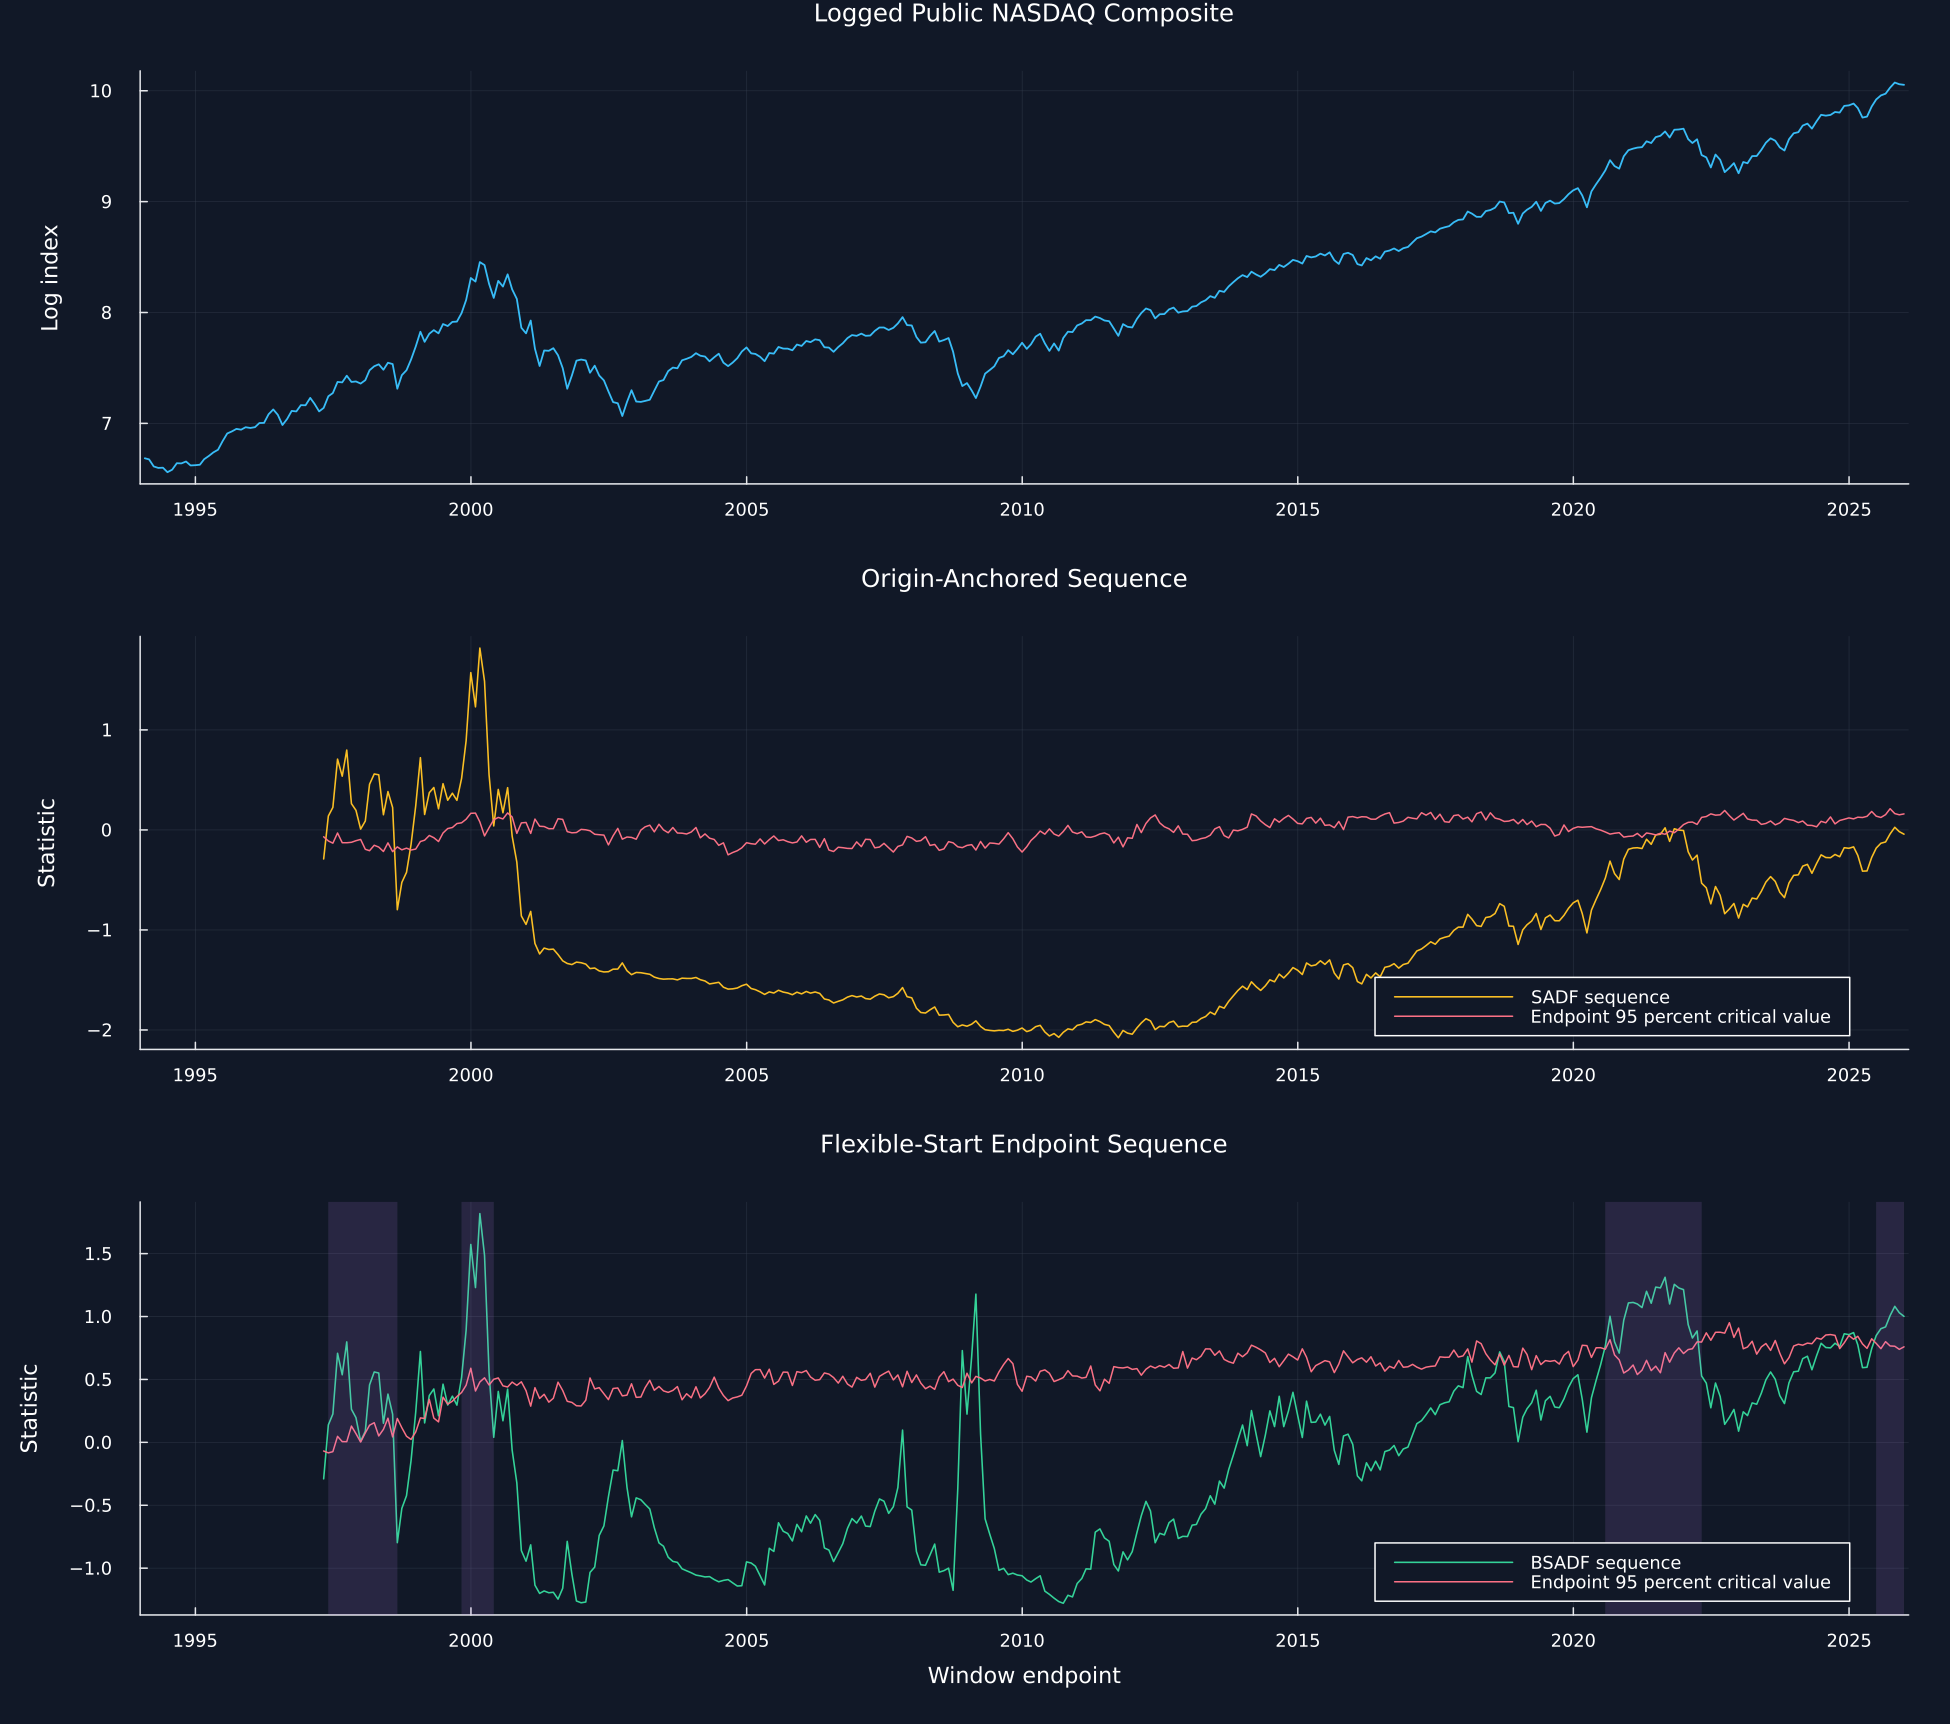

In [2]:
sample_length = length(log_price)
min_window = psy_minimum_window(sample_length)
min_duration = round(Int,log(sample_length))
sadf_sequence = get_sadf_sequence(log_price,min_window)
bsadf_sequence = get_bsadf_sequence(log_price,min_window)
critical = calibrate("public",sample_length,min_window,replay_matrix("psy_public_normals"))
sadf_critical_sequence = critical.sadf_sequence_cv
bsadf_critical_sequence = critical.bsadf_sequence_cv
sadf_statistic = maximum(sadf_sequence.values)
gsadf_statistic = get_gsadf_statistic(log_price,min_window)
public_episodes = get_bubble_episodes(monthly_time[bsadf_sequence.index],bsadf_sequence.values,bsadf_critical_sequence;min_duration=min_duration)
robust_public = robust_replay(log_price,min_window,replay_matrix("public_bootstrap_signs"),"Public NASDAQ",0)
recursive_public_summary = DataFrame("Method"=>["SADF","GSADF"],"Observed statistic"=>[sadf_statistic,gsadf_statistic],"Simulated 95 percent critical value"=>[critical.sadf_global_cv,critical.gsadf_global_cv],"Global rejection"=>[sadf_statistic>critical.sadf_global_cv,gsadf_statistic>critical.gsadf_global_cv],"Volatility-adjusted p-value"=>[robust_public.sadf_pvalue,robust_public.gsadf_pvalue],"Volatility-adjusted rejection"=>[robust_public.reject_sadf,robust_public.reject_gsadf])
save_table(recursive_public_summary,paths,"recursive_public_summary";caption="Recursive right-tailed tests on the fixed public NASDAQ sample.",label="tab:chapter11-recursive-public-summary")
critical_value_summary = DataFrame("Quantity"=>["Sample length","Minimum window","Null paths","Quantile","Minimum episode length","SADF critical value","GSADF critical value"],"Value"=>[string(sample_length),string(min_window),"499","0.95","$min_duration months",@sprintf("%.6f",critical.sadf_global_cv),@sprintf("%.6f",critical.gsadf_global_cv)])
save_table(critical_value_summary,paths,"critical_value_summary";caption="Finite-sample random-walk calibration used for the public recursive tests.",label="tab:chapter11-critical-value-summary")
public_candidate_episodes = DataFrame("Candidate"=>collect(1:length(public_episodes)),"First month above"=>[string(Date(start)) for (start,finish) in public_episodes],"First later month below"=>[string(Date(finish)) for (start,finish) in public_episodes],"Calendar months"=>[12(year(finish)-year(start))+month(finish)-month(start) for (start,finish) in public_episodes],"Global GSADF rejection"=>fill(gsadf_statistic>critical.gsadf_global_cv,length(public_episodes)))
save_table(public_candidate_episodes,paths,"public_candidate_episodes";caption="Endpoint threshold crossings in the public BSADF sequence. The global GSADF test is reported separately.",label="tab:chapter11-public-candidate-episodes")
p1 = plot(monthly_time,log_price;color=palette.cyan,linewidth=1.2,label=false,title="Logged Public NASDAQ Composite",ylabel="Log index",xticks=year_ticks)
p2 = plot(monthly_time[sadf_sequence.index],sadf_sequence.values;color=palette.amber,linewidth=1.05,label="SADF sequence",title="Origin-Anchored Sequence",ylabel="Statistic",xticks=year_ticks,legend=:bottomright)
plot!(p2,monthly_time[sadf_sequence.index],sadf_critical_sequence;color=palette.rose,linewidth=1,label="Endpoint 95 percent critical value")
p3 = plot(monthly_time[bsadf_sequence.index],bsadf_sequence.values;color=palette.green,linewidth=1.05,label="BSADF sequence",title="Flexible-Start Endpoint Sequence",xlabel="Window endpoint",ylabel="Statistic",xticks=year_ticks,legend=:bottomright)
plot!(p3,monthly_time[bsadf_sequence.index],bsadf_critical_sequence;color=palette.rose,linewidth=1,label="Endpoint 95 percent critical value")
for (start,finish) in public_episodes
    vspan!(p3,Dates.value.([start,finish]);color="#C084FC",alpha=.13,label=false)
end
save_figure(plot(p1,p2,p3;layout=(3,1),size=(1300,1150),left_margin=6Plots.mm,xlims=(Dates.value(first(monthly_time)-Day(31)),Dates.value(last(monthly_time)+Day(31)))),paths,"recursive_statistics_public")
save_data(DataFrame(position=sadf_sequence.index,time=monthly_time[sadf_sequence.index],sadf=sadf_sequence.values,bsadf=bsadf_sequence.values,sadf_cv=sadf_critical_sequence,bsadf_cv=bsadf_critical_sequence),paths,"recursive_public_paths");


## A Controlled Two-Episode Path

The controlled path alternates between random-walk periods, two mildly explosive intervals, and an explicit reset after each interval:

$$
y_t=
\begin{cases}
\rho y_{t-1}+\varepsilon_t,&a_j\leq t<b_j,\\
y_{a_j-1}+\varepsilon_t,&t=b_j,\\
y_{t-1}+\varepsilon_t,&\text{otherwise},
\end{cases}
\qquad
\rho=1.055,
\qquad
\varepsilon_t\sim\mathcal N(0,1).
$$

Here, $y_t$ is the controlled level; $t$ is the observation number; $(a_j,b_j)$ is explosive interval $j.$ $\rho=1.055$ is the explosive coefficient; $\varepsilon_t$ is an independent standard-normal shock; $\mathcal N(0,1)$ is its distribution. $y_{a_j-1}$ is the level immediately before episode $j$ and supplies the reset level at $b_j.$

Row,Method,Global statistic,Global 95 percent critical value,Detected episodes,True starts matched within 20,Mean nearest-start error,Detected intervals
,String,Float64,Float64,Int64,Int64,Float64,String
1,SADF,5.66001,1.49436,1,1,60.0,"[(93, 115)]"
2,BSADF and GSADF,7.23607,2.312,2,2,12.0,"[(90, 115), (214, 235)]"


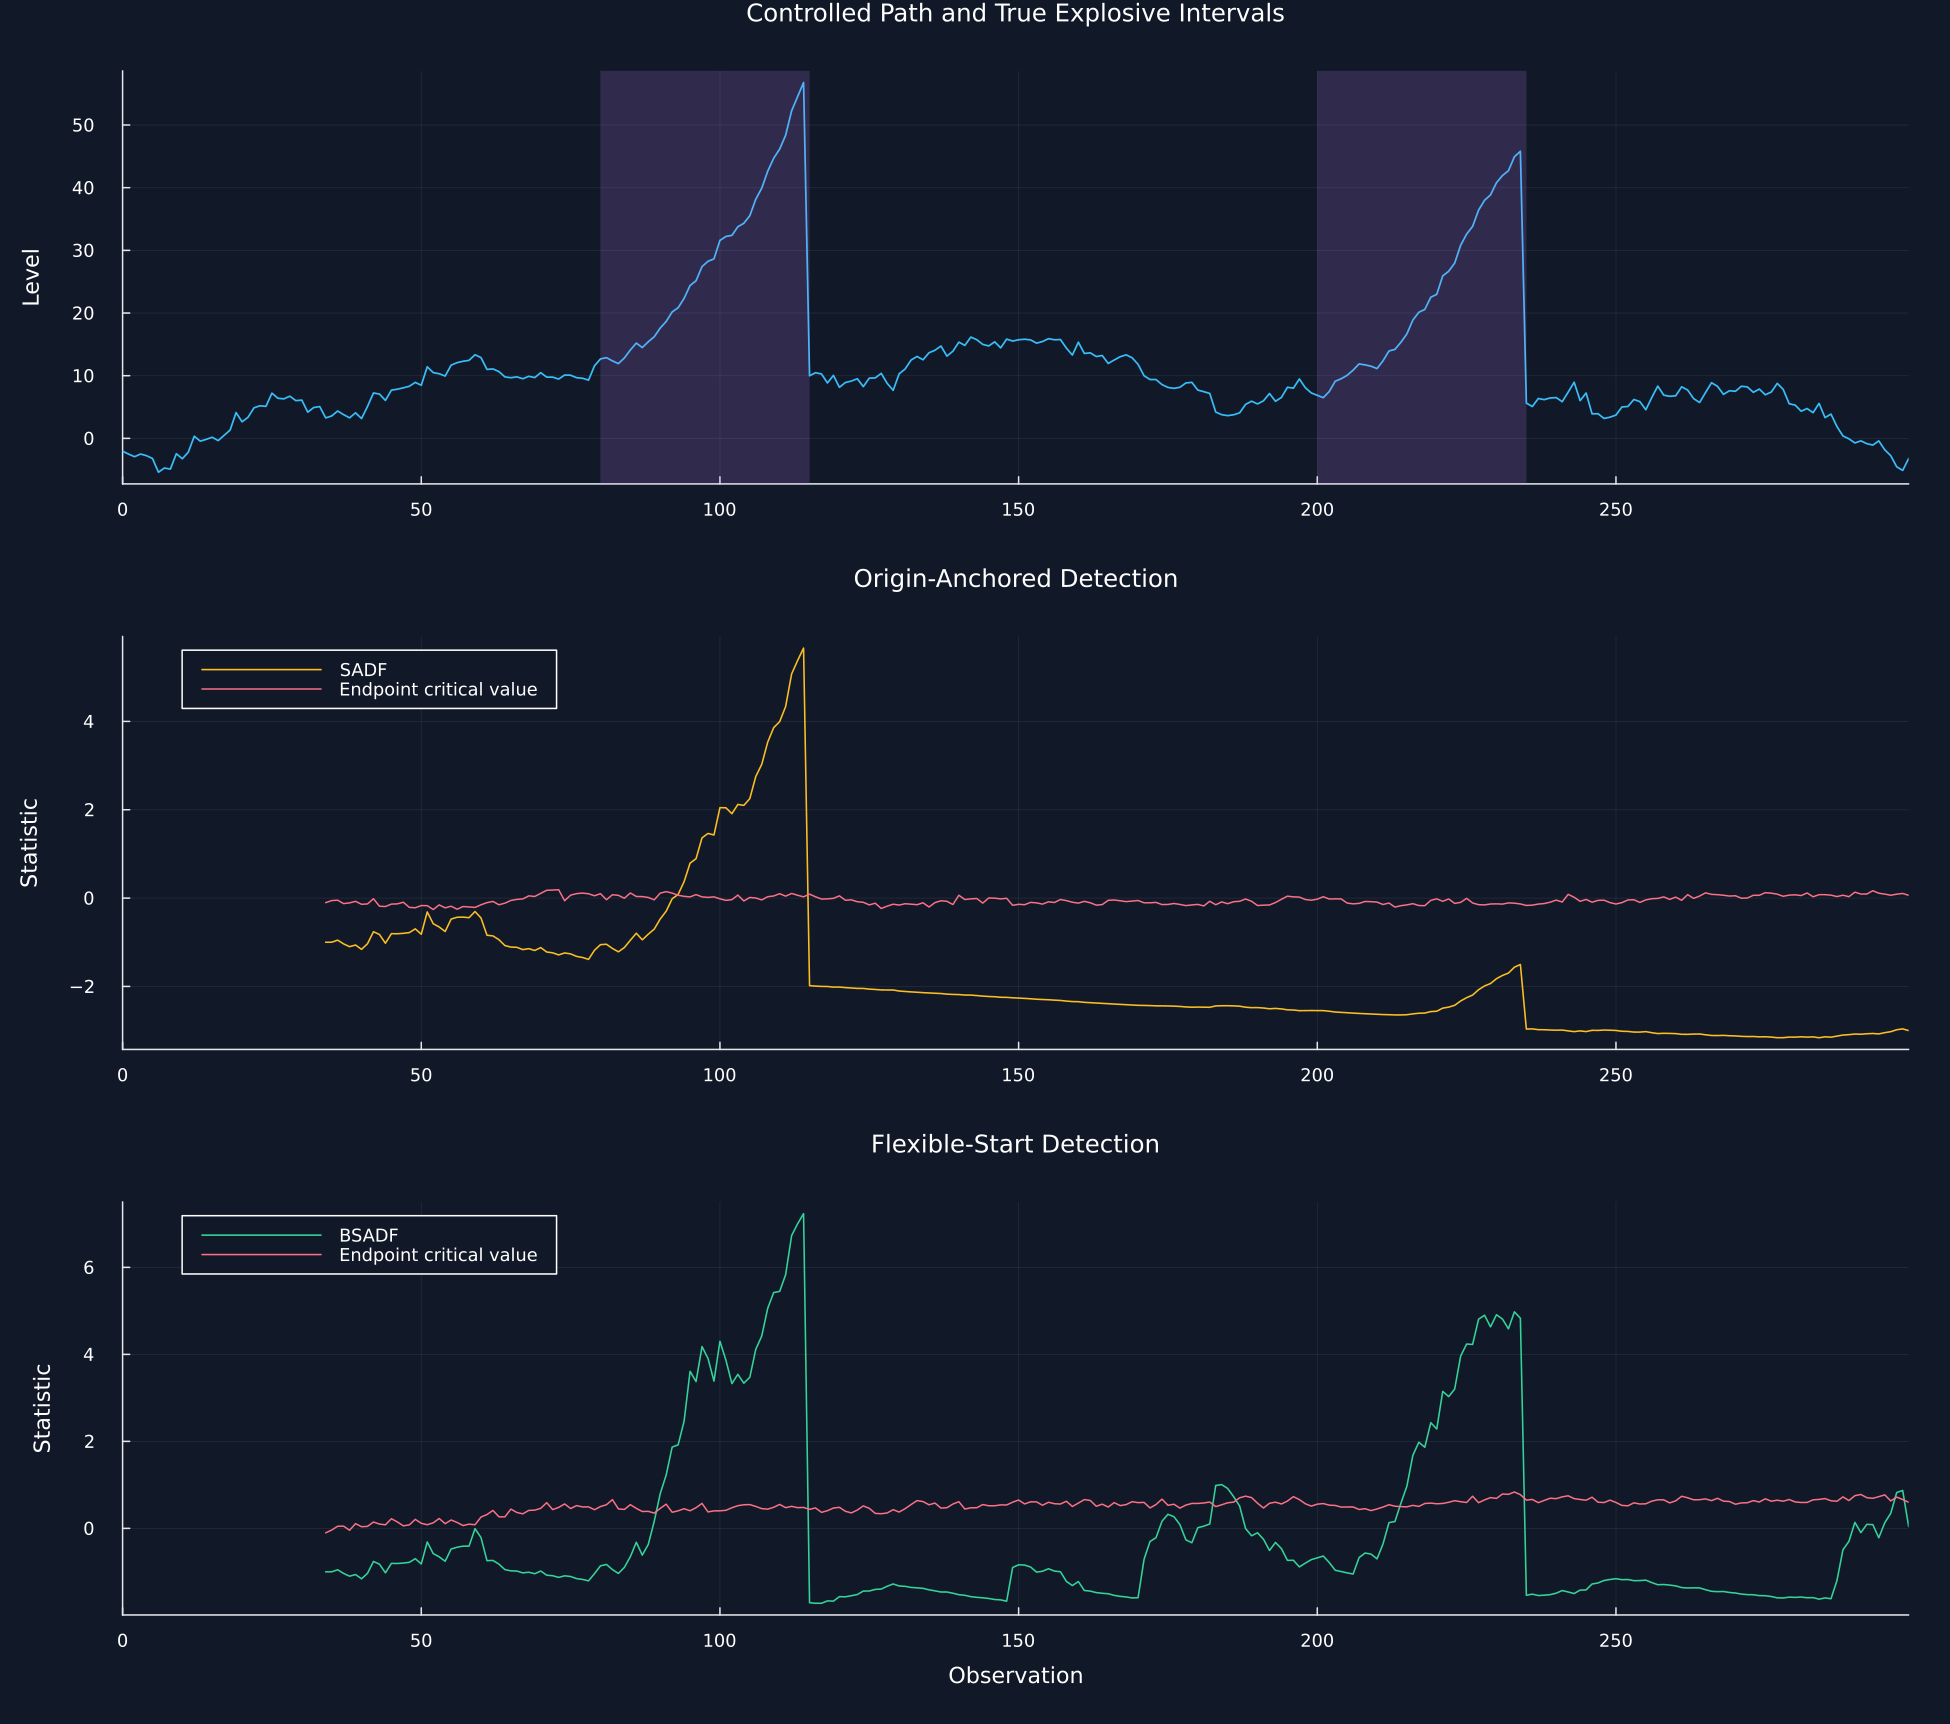

In [3]:
controlled_length = 300
true_intervals = [(80,115),(200,235)]
controlled_shocks = vec(replay_matrix("controlled_shocks"))
controlled_path = Vector{Float64}(undef,controlled_length)
controlled_path[1] = controlled_shocks[1]
for position in 2:controlled_length
    time = position-1
    active = findfirst(interval->interval[1]<=time<interval[2],true_intervals)
    ending = findfirst(interval->time==interval[2],true_intervals)
    if active!==nothing
        controlled_path[position] = 1.055controlled_path[position-1]+controlled_shocks[position]
    elseif ending!==nothing
        controlled_path[position] = controlled_path[true_intervals[ending][1]]+controlled_shocks[position]
    else
        controlled_path[position] = controlled_path[position-1]+controlled_shocks[position]
    end
end
controlled_min_window = psy_minimum_window(controlled_length)
controlled_critical = calibrate("controlled",controlled_length,controlled_min_window,replay_matrix("psy_controlled_normals"))
controlled_sadf = get_sadf_sequence(controlled_path,controlled_min_window)
controlled_bsadf = get_bsadf_sequence(controlled_path,controlled_min_window)
controlled_sadf_cv,controlled_bsadf_cv = controlled_critical.sadf_sequence_cv,controlled_critical.bsadf_sequence_cv
controlled_duration = round(Int,log(controlled_length))
sadf_episodes = get_bubble_episodes(controlled_sadf.index.-1,controlled_sadf.values,controlled_sadf_cv;min_duration=controlled_duration)
bsadf_episodes = get_bubble_episodes(controlled_bsadf.index.-1,controlled_bsadf.values,controlled_bsadf_cv;min_duration=controlled_duration)
function matched_starts(episodes;tolerance=20)
    starts = first.(episodes)
    errors = [isempty(starts) ? Inf : minimum(abs.(starts.-truth)) for (truth,finish) in true_intervals]
    finite = filter(isfinite,errors)
    return count(<=(tolerance),errors),isempty(finite) ? NaN : mean(finite)
end
sadf_matched,sadf_start_error = matched_starts(sadf_episodes)
bsadf_matched,bsadf_start_error = matched_starts(bsadf_episodes)
two_bubble_detection = DataFrame("Method"=>["SADF","BSADF and GSADF"],"Global statistic"=>[maximum(controlled_sadf.values),maximum(controlled_bsadf.values)],"Global 95 percent critical value"=>[controlled_critical.sadf_global_cv,controlled_critical.gsadf_global_cv],"Detected episodes"=>length.([sadf_episodes,bsadf_episodes]),"True starts matched within 20"=>[sadf_matched,bsadf_matched],"Mean nearest-start error"=>[sadf_start_error,bsadf_start_error],"Detected intervals"=>string.([sadf_episodes,bsadf_episodes]))
save_table(two_bubble_detection,paths,"two_bubble_detection";caption="Known-truth comparison on a path with two explosive intervals.",label="tab:chapter11-two-bubble-detection")
p1 = plot(0:controlled_length-1,controlled_path;color=palette.cyan,linewidth=1.15,label=false,title="Controlled Path and True Explosive Intervals",ylabel="Level")
for (start,finish) in true_intervals
    vspan!(p1,[start,finish];color="#C084FC",alpha=.18,label=false)
end
p2 = plot(controlled_sadf.index.-1,controlled_sadf.values;color=palette.amber,linewidth=1.05,label="SADF",title="Origin-Anchored Detection",ylabel="Statistic",legend=:topleft)
plot!(p2,controlled_sadf.index.-1,controlled_sadf_cv;color=palette.rose,linewidth=1,label="Endpoint critical value")
p3 = plot(controlled_bsadf.index.-1,controlled_bsadf.values;color=palette.green,linewidth=1.05,label="BSADF",title="Flexible-Start Detection",xlabel="Observation",ylabel="Statistic",legend=:topleft)
plot!(p3,controlled_bsadf.index.-1,controlled_bsadf_cv;color=palette.rose,linewidth=1,label="Endpoint critical value")
save_figure(plot(p1,p2,p3;layout=(3,1),size=(1300,1150),left_margin=6Plots.mm,xlims=(0,controlled_length-1)),paths,"two_bubble_detection")
save_data(DataFrame(position=0:controlled_length-1,innovation=controlled_shocks,value=controlled_path),paths,"controlled_two_episode_path");
save_data(DataFrame(position=controlled_sadf.index.-1,sadf=controlled_sadf.values,bsadf=controlled_bsadf.values,sadf_cv=controlled_sadf_cv,bsadf_cv=controlled_bsadf_cv),paths,"controlled_recursive_paths");
save_data(DataFrame(method=vcat(fill("SADF",length(sadf_episodes)),fill("BSADF",length(bsadf_episodes))),start=first.(vcat(sadf_episodes,bsadf_episodes)),finish=last.(vcat(sadf_episodes,bsadf_episodes))),paths,"controlled_detected_episodes");


## Volatility Adjustment

Random sign changes preserve the size pattern of observed shocks while forming a null distribution for the recursive statistic:

$$
\widetilde\varepsilon_t=\Delta y_t-\overline{\Delta y},
\qquad
y_t^{*(b)}=y_0+\sum_{j=1}^{t}\xi_j^{(b)}\widetilde\varepsilon_j,
\qquad
\xi_j^{(b)}\in\{-1,1\},
\qquad
\widehat p=\frac{1+\sum_{b=1}^{B}\mathbf 1\{S_b^*\geq S_{\mathrm{obs}}\}}{B+1}.
$$

Here, $\widetilde\varepsilon_t$ is a demeaned first difference; $\overline{\Delta y}$ is the average first difference. $b$ labels one resample; $B$ is the number of resamples; $\xi_j^{(b)}$ is an independent sign; $y_t^{*(b)}$ is a resampled path. $S_{\mathrm{obs}}$ is the observed SADF or GSADF value; $S_b^*$ is its resampled value; $\mathbf 1\{\cdot\}$ is an indicator; $\widehat p$ is the adjusted p-value.

Row,Scenario,Calibration,Rejections,Repetitions,Rejection rate,Simulation standard error
,String,String,Int64,Int64,Float64,Float64
1,Constant volatility,Constant-volatility critical value,3,32,0.09375,0.051527
2,Constant volatility,Volatility-adjusted signs,4,32,0.125,0.0584634
3,Sixfold volatility break,Constant-volatility critical value,25,32,0.78125,0.0730792
4,Sixfold volatility break,Volatility-adjusted signs,2,32,0.0625,0.0427908


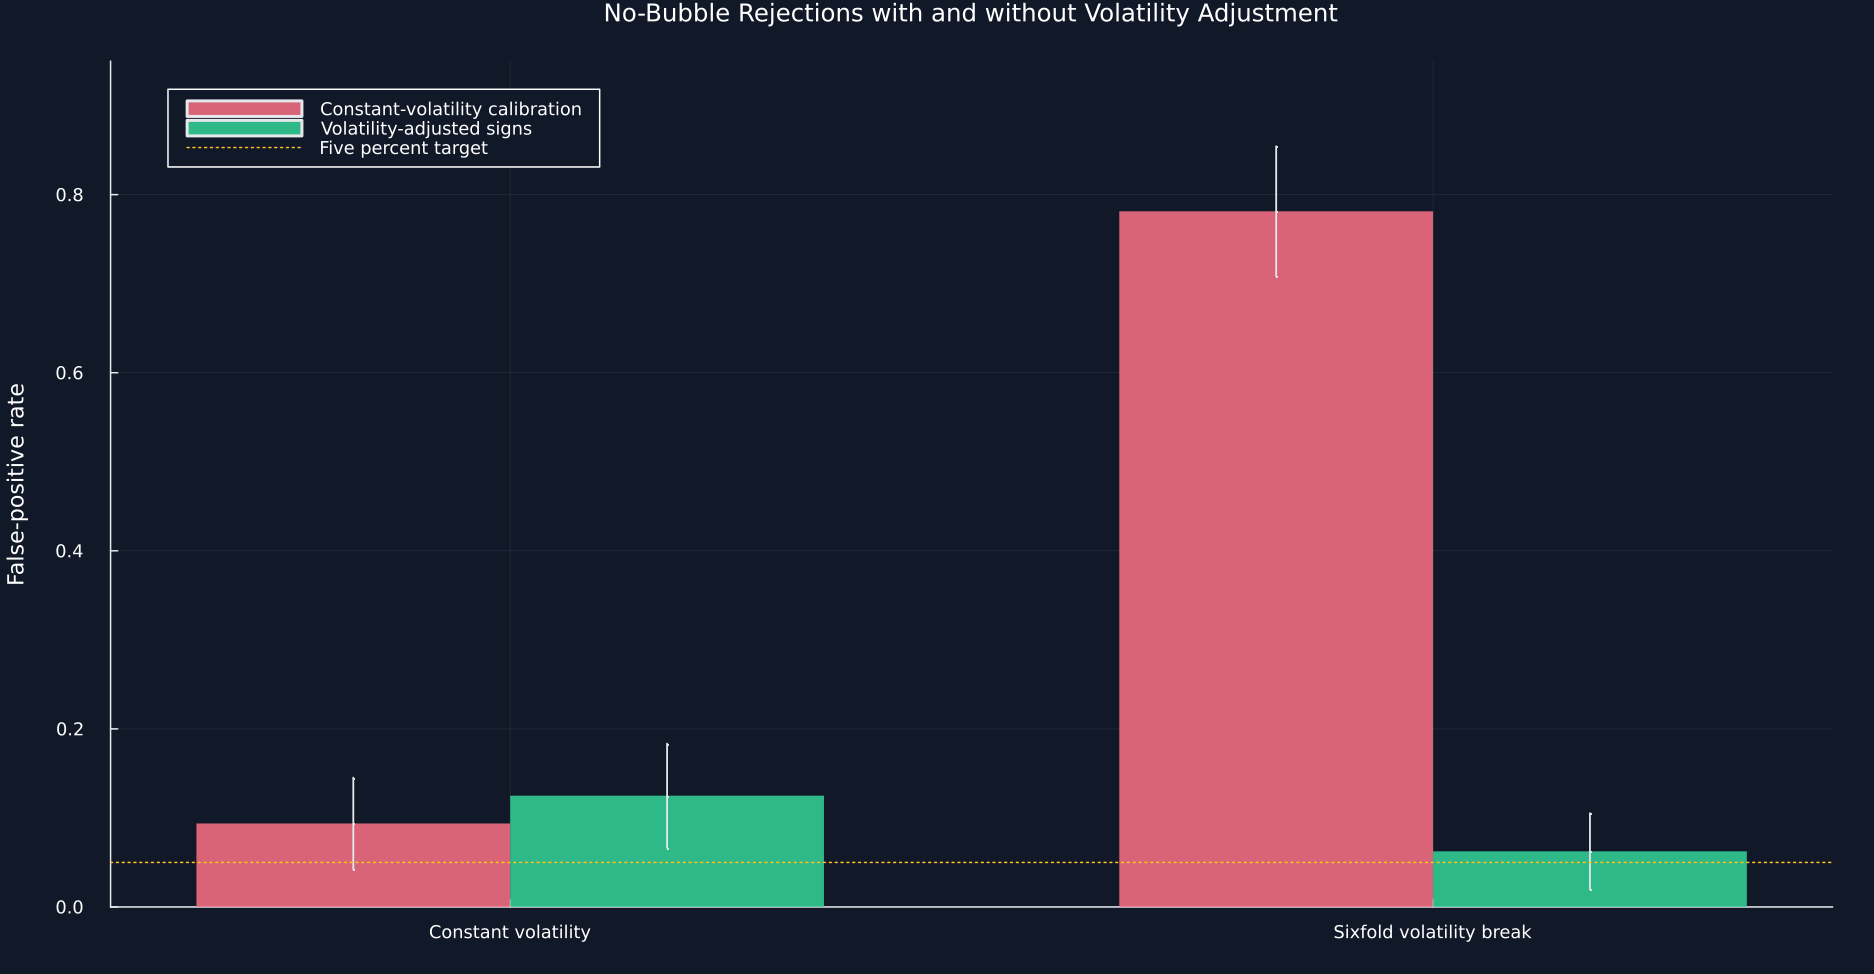

In [4]:
variance_length = 130
variance_min_window = psy_minimum_window(variance_length)
variance_repetitions = 32
bootstrap_repetitions = 79
plain_calibration = calibrate("variance",variance_length,variance_min_window,replay_matrix("psy_variance_normals"))
plain_critical = plain_calibration.sadf_global_cv
variance_normals = replay_matrix("variance_normals")
variance_signs = replay_matrix("variance_bootstrap_signs")
variance_rows = NamedTuple[]
variance_run_rows = NamedTuple[]
variance_paths = DataFrame()
for (scenario,strength) in [("Constant volatility",1.),("Sixfold volatility break",6.)]
    plain_rejections,adjusted_rejections = 0,0
    for repetition in 0:variance_repetitions-1
        sigma = ones(variance_length)
        sigma[variance_length÷2+1:end] .= strength
        variance_path = cumsum(vec(variance_normals[repetition+1,:]).*sigma)
        sign_selection = variance_signs[:,1].==repetition
        signs = variance_signs[sign_selection,3:end]
        adjusted = robust_replay(variance_path,variance_min_window,signs,scenario,repetition)
        plain_rejections += adjusted.sadf>plain_critical
        adjusted_rejections += adjusted.sadf_pvalue<.05
        push!(variance_run_rows,(scenario=scenario,repetition=repetition,sadf=adjusted.sadf,gsadf=adjusted.gsadf,sadf_pvalue=adjusted.sadf_pvalue,gsadf_pvalue=adjusted.gsadf_pvalue,plain_reject=adjusted.sadf>plain_critical,adjusted_reject=adjusted.reject_sadf,plain_critical=plain_critical))
        append!(variance_paths,DataFrame(scenario=fill(scenario,variance_length),repetition=fill(repetition,variance_length),position=0:variance_length-1,innovation=vec(variance_normals[repetition+1,:]),sigma=sigma,value=variance_path);cols=:union)
    end
    for (calibration,count) in [("Constant-volatility critical value",plain_rejections),("Volatility-adjusted signs",adjusted_rejections)]
        rate = count/variance_repetitions
        push!(variance_rows,(scenario=scenario,calibration=calibration,rejections=count,repetitions=variance_repetitions,rate=rate,error=sqrt(rate*(1-rate)/variance_repetitions)))
    end
end
volatility_break_size = DataFrame(variance_rows)
rename!(volatility_break_size,["Scenario","Calibration","Rejections","Repetitions","Rejection rate","Simulation standard error"])
save_table(volatility_break_size,paths,"volatility_break_size";caption="False-positive rates under two no-bubble random walks. Simulation uncertainty is shown because only 32 repetitions are used.",label="tab:chapter11-volatility-break-size")
scenarios = ["Constant volatility","Sixfold volatility break"]
plain_rows = volatility_break_size[volatility_break_size.Calibration.=="Constant-volatility critical value",:]
adjusted_rows = volatility_break_size[volatility_break_size.Calibration.=="Volatility-adjusted signs",:]
figure = bar((1:2).- .17,plain_rows[!,"Rejection rate"];bar_width=.34,color=palette.rose,alpha=.85,linealpha=0,label="Constant-volatility calibration",xticks=(1:2,scenarios),ylims=(0,.95),ylabel="False-positive rate",title="No-Bubble Rejections with and without Volatility Adjustment",legend=:topleft,size=(1250,650))
bar!(figure,(1:2).+ .17,adjusted_rows[!,"Rejection rate"];bar_width=.34,color=palette.green,alpha=.85,linealpha=0,label="Volatility-adjusted signs")
scatter!(figure,(1:2).- .17,plain_rows[!,"Rejection rate"];yerror=plain_rows[!,"Simulation standard error"],markersize=0,color=palette.text,linealpha=1,linewidth=1.2,label=false)
scatter!(figure,(1:2).+ .17,adjusted_rows[!,"Rejection rate"];yerror=adjusted_rows[!,"Simulation standard error"],markersize=0,color=palette.text,linealpha=1,linewidth=1.2,label=false)
hline!(figure,[.05];color=palette.amber,linewidth=1,linestyle=:dot,label="Five percent target")
save_figure(figure,paths,"volatility_adjustment_experiment")
save_data(DataFrame(variance_run_rows),paths,"volatility_break_runs");
save_data(variance_paths,paths,"volatility_break_paths");
save_data(DataFrame(bootstrap_records),paths,"wild_bootstrap_statistics");


## Tests

In [5]:
@assert sample_length==384
@assert min_window==39
@assert length(sadf_sequence.values)==length(bsadf_sequence.values)==sample_length-min_window
@assert sadf_sequence.index==bsadf_sequence.index
@assert sadf_statistic≈maximum(sadf_sequence.values)
@assert gsadf_statistic≈maximum(bsadf_sequence.values)
@assert isapprox(sadf_statistic,1.8179690572971872;atol=1e-10)
@assert isapprox(gsadf_statistic,1.8179690572971872;atol=1e-10)
@assert critical.gsadf_global_cv>critical.sadf_global_cv
@assert recursive_public_summary[!,"Global rejection"]==[true,false]
@assert !any(recursive_public_summary[!,"Volatility-adjusted rejection"])
@assert robust_public.sadf_pvalue==.21
@assert robust_public.gsadf_pvalue==.49
@assert length(public_episodes)>=3
@assert all(public_candidate_episodes[!,"Calendar months"].>=min_duration)
@assert controlled_min_window==34
@assert maximum(controlled_sadf.values)>controlled_critical.sadf_global_cv
@assert maximum(controlled_bsadf.values)>controlled_critical.gsadf_global_cv
@assert length(sadf_episodes)==1
@assert length(bsadf_episodes)==2
@assert sadf_matched==1
@assert bsadf_matched==2
@assert variance_repetitions==32
@assert bootstrap_repetitions==79
@assert size(volatility_break_size)==(4,6)
@assert all(0 .<=volatility_break_size[!,"Rejection rate"].<=1)
@assert plain_rows[2,"Rejection rate"]>=.60
@assert adjusted_rows[2,"Rejection rate"]<=.20
@assert plain_rows[2,"Rejection rate"]>adjusted_rows[2,"Rejection rate"]
@assert isfile(joinpath(paths.figures,"recursive_statistics_public.pdf"))
@assert isfile(joinpath(paths.figures,"two_bubble_detection.pdf"))
@assert isfile(joinpath(paths.figures,"volatility_adjustment_experiment.pdf"))
@assert isfile(joinpath(paths.tables,"recursive_public_summary.tex"))
@assert isfile(joinpath(paths.tables,"critical_value_summary.tex"))
@assert isfile(joinpath(paths.tables,"public_candidate_episodes.tex"))
@assert isfile(joinpath(paths.tables,"two_bubble_detection.tex"))
@assert isfile(joinpath(paths.tables,"volatility_break_size.tex"))
